# IN6227 Assignment 1 — Variant 1
## Part 1: Data Exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
RANDOM_STATE = 42

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
print("train:", train.shape, " test:", test.shape)
train.head()

train: (31112, 16)  test: (13334, 16)


,geological_era,weather_pattern,region,aptitude_score,performance_score,stability_index,personal_interest,load_ratio,brew_preference,instrument,species,index_weight,mineral_type,activity_duration,composite_rank,label
0,Triassic,Heatwave,Texas,325.58,34.95,1.503,Foraging,23.878,Espresso,Dulcimer,Lynx,8.63,Marble,77.98,2.093,no
1,Triassic,Monsoon,Texas,333.63,256.50,3.283,Falconry,28.617,Espresso,Cello,Bison,14.22,Opal,95.76,3.028,no
2,Triassic,Monsoon,Texas,503.96,385.00,3.676,Astronomy,22.582,Espresso,Cello,Lynx,11.04,Diamond,114.03,4.564,yes
3,Triassic,Heatwave,Texas,404.61,156.44,2.812,Calligraphy,28.002,Latte,Oboe,Lynx,15.64,Sapphire,113.58,3.053,no
4,Triassic,Heatwave,Texas,358.89,144.05,2.735,Beekeeping,22.062,Espresso,Oboe,Lynx,10.99,Granite,79.40,2.730,no


### 1.1 Feature types

In [3]:
TARGET = "label"
num_cols = train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in train.columns if c not in num_cols + [TARGET]]
print("Numeric (%d):" % len(num_cols), num_cols)
print("Categorical (%d):" % len(cat_cols), cat_cols)

Numeric (7): ['aptitude_score', 'performance_score', 'stability_index', 'load_ratio', 'index_weight', 'activity_duration', 'composite_rank']
Categorical (8): ['geological_era', 'weather_pattern', 'region', 'personal_interest', 'brew_preference', 'instrument', 'species', 'mineral_type']


### 1.2 Target distribution — is the data imbalanced?

In [5]:
print(train[TARGET].value_counts(dropna=False))
print()
print(train[TARGET].value_counts(normalize=True).round(3))

label
no     23645
yes     7464
NaN        3
Name: count, dtype: int64

label
no     0.76
yes    0.24
Name: proportion, dtype: float64


### 1.3 Missing values (explicit NaN)

In [7]:
missing = pd.DataFrame({
    "train_missing": train.isnull().sum(),
    "test_missing": test.isnull().sum(),
})
print(missing[missing.sum(axis=1) > 0])
print("\nRows with any NaN -> train:", train.isnull().any(axis=1).sum(),
      "| test:", test.isnull().any(axis=1).sum())
print("Rows with missing label -> train:", train[TARGET].isnull().sum(),
      "| test:", test[TARGET].isnull().sum())

                   train_missing  test_missing
geological_era                 2             2
weather_pattern                3             0
region                         4             1
aptitude_score                 4             1
performance_score              2             0
stability_index                2             1
personal_interest              6             1
load_ratio                     2             1
brew_preference                7             3
instrument                     3             2
species                        3             2
index_weight                   3             1
mineral_type                   3             0
activity_duration              2             1
composite_rank                 1             4
label                          3             1

Rows with any NaN -> train: 50 | test: 21
Rows with missing label -> train: 3 | test: 1


### 1.4 Hidden missing values (placeholder strings)
Missing values are not always NaN — check for strings such as `?`, `Unknown`, empty strings.

In [9]:
placeholders = ["?", "", "unknown", "Unknown", "NA", "N/A", "None", "-"]
for c in cat_cols:
    s = train[c].astype(str).str.strip()
    hits = s[s.isin(placeholders)].value_counts()
    if len(hits):
        print(c, hits.to_dict())

# Do the two 'Unknown' columns occur in the same rows?
print(pd.crosstab(train["personal_interest"] == "Unknown",
                  train["species"] == "Unknown",
                  rownames=["interest=Unknown"], colnames=["species=Unknown"]))

# Is 'Unknown' informative? Compare positive rate
pos = (train[TARGET] == "yes")
print("\nPositive rate overall:", round(pos.mean(), 3))
print("Positive rate when species == Unknown:", round(pos[train["species"] == "Unknown"].mean(), 3))

personal_interest {'Unknown': 1767}
species {'Unknown': 1760}
species=Unknown   False  True 
interest=Unknown              
False             29345      0
True                  7   1760

Positive rate overall: 0.24
Positive rate when species == Unknown: 0.087


### 1.5 Duplicates

In [11]:
print("Duplicate rows -> train:", train.duplicated().sum(), "| test:", test.duplicated().sum())

Duplicate rows -> train: 0 | test: 0


### 1.6 Numeric features: summary, suspicious zeros, capped values, outliers

In [13]:
print(train[num_cols].describe().T.round(3))

                     count     mean      std     min      25%      50%      75%       max
aptitude_score     31108.0  342.134   68.925  90.000  310.598  333.515  402.562   510.000
performance_score  31110.0  296.493  187.620   0.000  146.572  275.385  420.170  1010.000
stability_index    31110.0    3.156    0.849   0.000    2.751    3.351    3.762     4.625
load_ratio         31110.0   24.423    9.920   0.000   19.272   23.689   27.657   143.717
index_weight       31109.0   12.722    7.747   0.000    7.520   11.730   16.230    99.620
activity_duration  31110.0   80.361   25.515   0.000   72.740   80.330   90.258   205.000
composite_rank     31111.0    3.239    0.870   0.589    2.591    3.199    3.838     6.876


In [15]:
print("Exact zeros per column:")
print((train[num_cols] == 0).sum())

z = train[train["performance_score"] == 0]
print("\nRows with performance_score == 0:", len(z),
      "| of these, stability_index == 0:", (z["stability_index"] == 0).sum(),
      "| label:", z[TARGET].value_counts().to_dict())

print("\nRows at the maximum value (possible capping):")
for c in ["aptitude_score", "performance_score", "activity_duration"]:
    print(" ", c, "max =", train[c].max(), "count =", (train[c] == train[c].max()).sum())

Exact zeros per column:
aptitude_score         0
performance_score    265
stability_index      265
load_ratio            38
index_weight           4
activity_duration     38
composite_rank         0
dtype: int64

Rows with performance_score == 0: 265 | of these, stability_index == 0: 265 | label: {'no': 265}

Rows at the maximum value (possible capping):
  aptitude_score max = 510.0 count = 35
  performance_score max = 1010.0 count = 7
  activity_duration max = 205.0 count = 10


In [17]:
rows = []
for c in num_cols:
    q1, q3 = train[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((train[c] < q1 - 1.5 * iqr) | (train[c] > q3 + 1.5 * iqr)).sum()
    rows.append([c, n_out, round(100 * n_out / len(train), 1), round(train[c].skew(), 2)])
print(pd.DataFrame(rows, columns=["feature", "IQR_outliers", "pct", "skew"]))

             feature  IQR_outliers   pct  skew
0     aptitude_score           617   2.0 -0.29
1  performance_score           154   0.5  0.55
2    stability_index          1128   3.6 -1.23
3         load_ratio          2527   8.1  1.71
4       index_weight          1017   3.3  1.51
5  activity_duration          5350  17.2  0.20
6     composite_rank           115   0.4  0.26


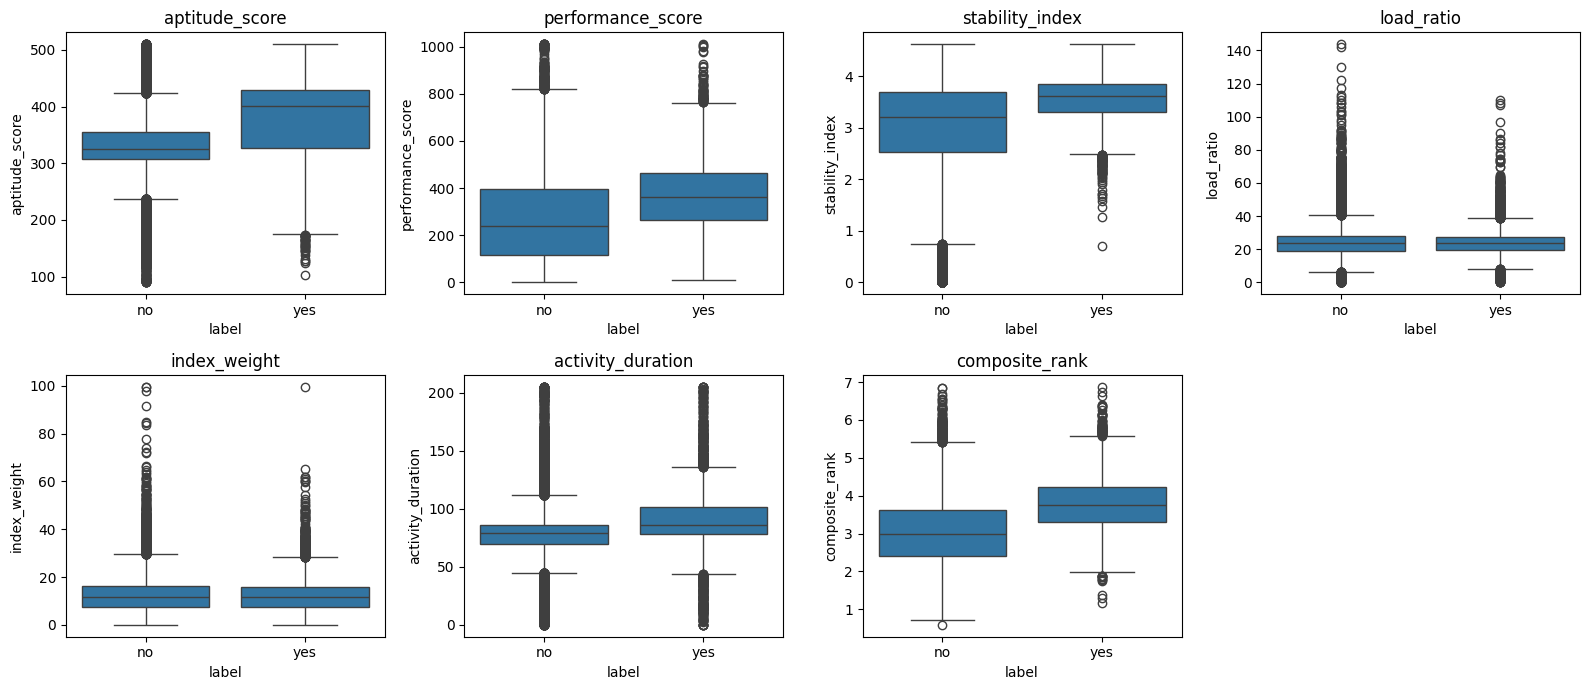

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, num_cols):
    sns.boxplot(data=train, x=TARGET, y=c, ax=ax)
    ax.set_title(c)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### 1.7 Correlation between numeric features (redundancy check)

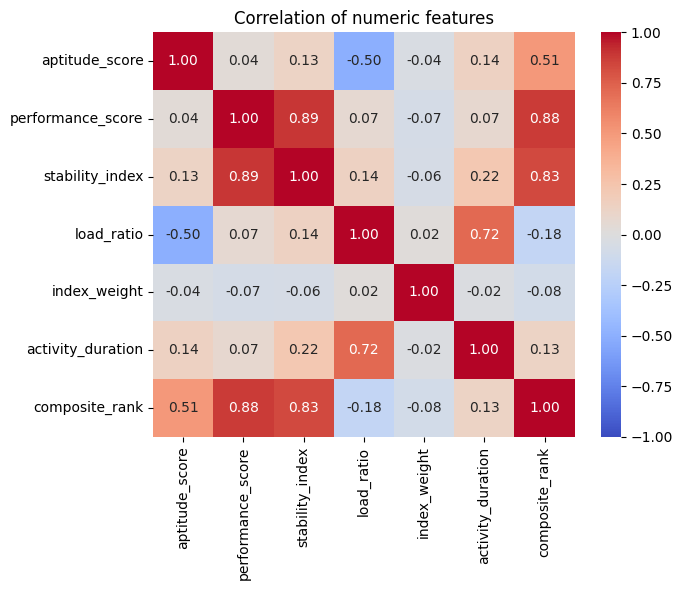

In [21]:
corr = train[num_cols].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation of numeric features")
plt.tight_layout()
plt.show()

### 1.8 Categorical features: cardinality, dominant levels, positive rate per level

In [25]:
rows = []
for c in cat_cols:
    vc = train[c].value_counts()
    rows.append([c, train[c].nunique(), vc.index[0], round(vc.iloc[0] / len(train), 3),
                 (vc < 100).sum()])
print(pd.DataFrame(rows, columns=["feature", "n_levels", "top_level", "top_share", "levels_<100_rows"]))

             feature  n_levels  top_level  top_share  levels_<100_rows
0     geological_era         5   Triassic      0.856                 0
1    weather_pattern         7    Monsoon      0.459                 1
2             region        21      Texas      0.897                13
3  personal_interest        11  Astronomy      0.127                 0
4    brew_preference         2   Espresso      0.668                 0
5         instrument         6      Cello      0.404                 0
6            species         7       Lynx      0.698                 0
7       mineral_type        16     Marble      0.324                 1


In [27]:
for c in cat_cols:
    rate = train.groupby(c)[TARGET].apply(lambda s: (s == "yes").mean())
    cnt = train[c].value_counts()
    print("\n==", c)
    print(pd.DataFrame({"count": cnt, "pos_rate": rate.round(3)}).sort_values("count", ascending=False).head(10))


== geological_era
                count  pos_rate
geological_era                 
Triassic        26642     0.255
Jurassic         2934     0.120
Devonian          984     0.251
Cambrian          298     0.107
Permian           252     0.123

== weather_pattern
                 count  pos_rate
weather_pattern                 
Monsoon          14274     0.447
Heatwave         10251     0.044
Blizzard          4191     0.104
Fog                987     0.064
Frost              978     0.082
Drizzle            404     0.106
Typhoon             24     0.375

== region
              count  pos_rate
region                       
Texas         27915     0.245
Arizona         608     0.058
Wyoming         553     0.248
Other           532     0.201
South-Dakota    178     0.219
Oregon          131     0.290
Vermont         128     0.383
Kentucky        123     0.114
Rhode-Island     95     0.074
Wisconsin        92     0.391

== personal_interest
                   count  pos_rate
personal_int

In [29]:
unseen = {c: set(test[c].dropna()) - set(train[c].dropna()) for c in cat_cols}
print("Categories in test but not in train:", {k: v for k, v in unseen.items() if v} or "none")

Categories in test but not in train: none


### 1.9 Mutual Information

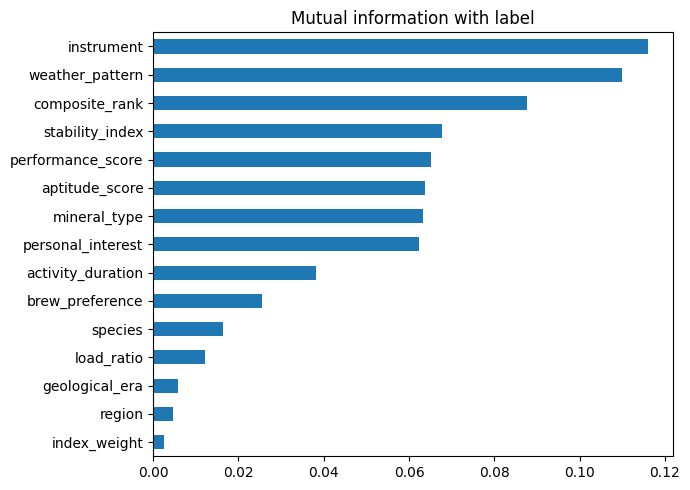

instrument           0.116
weather_pattern      0.110
composite_rank       0.088
stability_index      0.068
performance_score    0.065
aptitude_score       0.064
mineral_type         0.063
personal_interest    0.062
activity_duration    0.038
brew_preference      0.026
species              0.016
load_ratio           0.012
geological_era       0.006
region               0.005
index_weight         0.003
dtype: float64


In [32]:
from sklearn.feature_selection import mutual_info_classif

d = train.dropna()
X_mi = d.drop(columns=TARGET).copy()
for c in cat_cols:
    X_mi[c] = X_mi[c].astype("category").cat.codes
mi = mutual_info_classif(X_mi, d[TARGET] == "yes",
                         discrete_features=[c in cat_cols for c in X_mi.columns],
                         random_state=RANDOM_STATE)
mi = pd.Series(mi, index=X_mi.columns).sort_values()
mi.plot.barh(figsize=(7, 5), title="Mutual information with label")
plt.tight_layout()
plt.show()
print(mi.sort_values(ascending=False).round(3))